# Iris Species Classifier: Model Development and Evaluation

This notebook documents the model behind the FastAPI **Iris Predictor** app. It covers:

1. Loading and inspecting the UCI Iris data
2. Exploratory data analysis
3. Training a Random Forest classifier
4. Evaluation: hold-out metrics, confusion matrix, and cross-validated model comparison
5. Feature importance
6. Verifying the saved `.pkl` artifact and the running web app

**Dataset:** [UCI Iris](https://archive.ics.uci.edu/dataset/53/iris), 150 samples, 4 numeric features, 3 balanced classes.

## 1. Setup

In [2]:
import re
import sys
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")

# Work from the project root whether the notebook is opened from /notebooks or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import train_model  # reuse the same paths and loader as the app's training script

RANDOM_STATE = 42
FEATURES = train_model.COLUMNS[:4]
COLORS = {"Iris-setosa": "tab:blue", "Iris-versicolor": "tab:orange", "Iris-virginica": "tab:green"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 2. Load the data

In [3]:
if not train_model.DATA_PATH.exists():
    train_model.download_data()  # downloads iris.zip from UCI and extracts iris.data

df = pd.read_csv(
    train_model.DATA_PATH, header=None, names=train_model.COLUMNS, skip_blank_lines=True
).dropna()

print(f"Shape: {df.shape}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
df.head()

Shape: (150, 5)
Missing values: 0
Duplicate rows: 3


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Class balance:")
print(df["species"].value_counts().to_string())
print()
df[FEATURES].describe().round(2)

Class balance:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50



,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 3. Exploratory data analysis

The question is whether the species are separable using these four measurements.

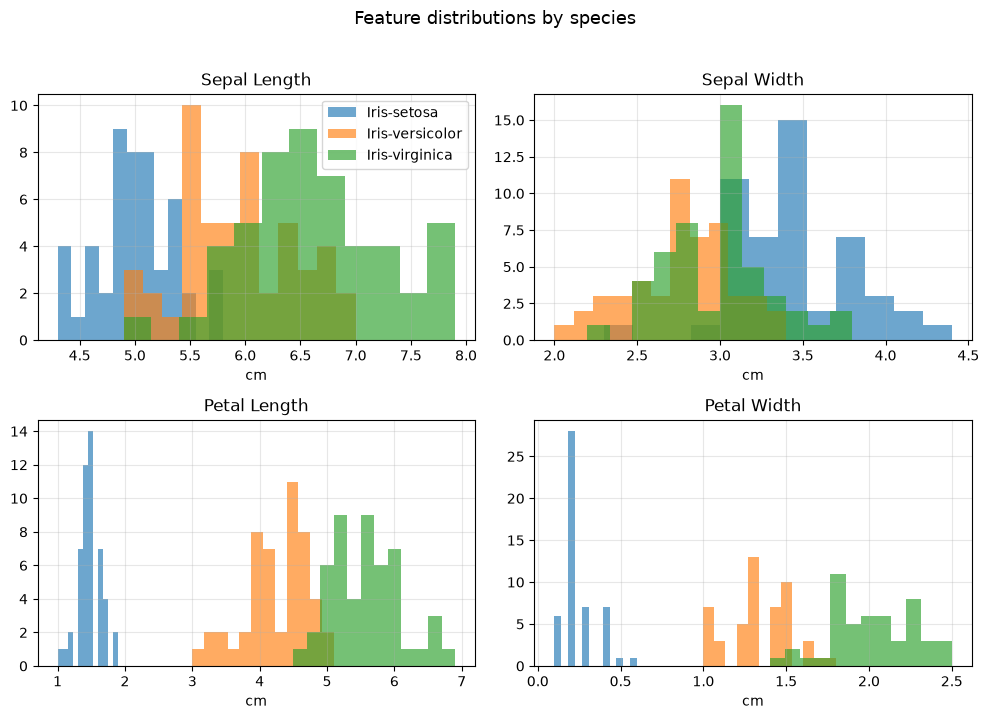

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.ravel(), FEATURES):
    for species, group in df.groupby("species"):
        ax.hist(group[feature], bins=12, alpha=0.65, label=species, color=COLORS[species])
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("cm")
axes[0, 0].legend()
fig.suptitle("Feature distributions by species", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

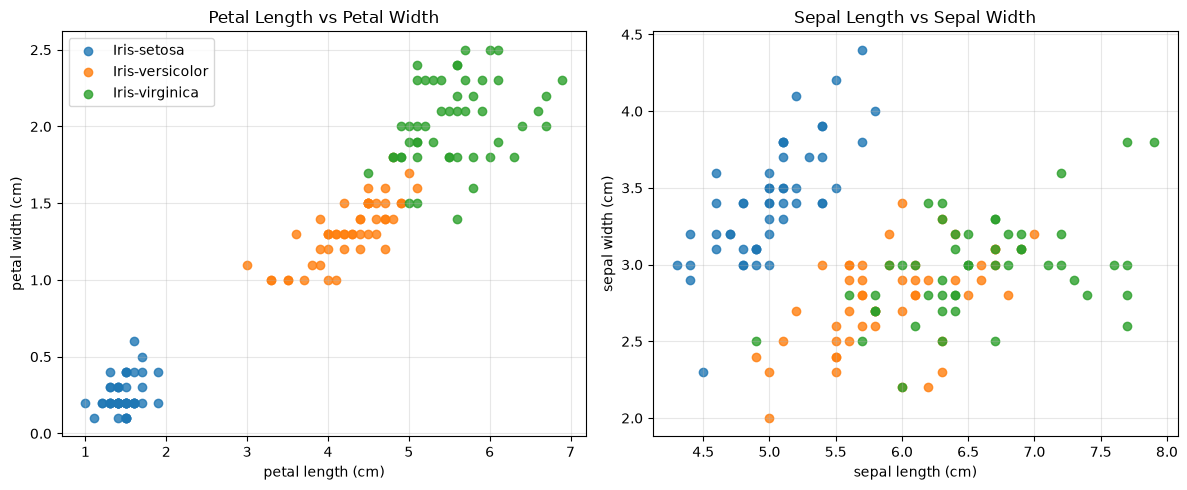

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (x, y_) in zip(axes, [("petal_length", "petal_width"), ("sepal_length", "sepal_width")]):
    for species, group in df.groupby("species"):
        ax.scatter(group[x], group[y_], label=species, color=COLORS[species], alpha=0.8)
    ax.set_xlabel(x.replace("_", " ") + " (cm)")
    ax.set_ylabel(y_.replace("_", " ") + " (cm)")
    ax.set_title(f"{x.replace('_', ' ').title()} vs {y_.replace('_', ' ').title()}")
axes[0].legend()
plt.tight_layout()
plt.show()

In [7]:
df[FEATURES].corr().round(2)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.00,-0.11,0.87,0.82
sepal_width,-0.11,1.00,-0.42,-0.36
petal_length,0.87,-0.42,1.00,0.96
petal_width,0.82,-0.36,0.96,1.00


**Observations**

- The classes are perfectly balanced (50 each), so plain accuracy is a fair headline metric.
- *Iris-setosa* is clearly separated, mainly by petal size.
- *Iris-versicolor* and *Iris-virginica* overlap, so almost all classification errors will come from that pair.
- Petal measurements separate the classes better than sepal measurements.

## 4. Train the model

A stratified 80/20 split keeps class proportions equal in both sets. The configuration below is identical to `train_model.py`, so the notebook reproduces the model the app serves.

In [8]:
X = df[FEATURES].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

Train samples: 120 | Test samples: 30


## 5. Evaluate on the hold-out set

In [9]:
y_pred = model.predict(X_test)
holdout_accuracy = accuracy_score(y_test, y_pred)

print(f"Hold-out accuracy: {holdout_accuracy:.3f}\n")
print(classification_report(y_test, y_pred))

Hold-out accuracy: 0.900

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



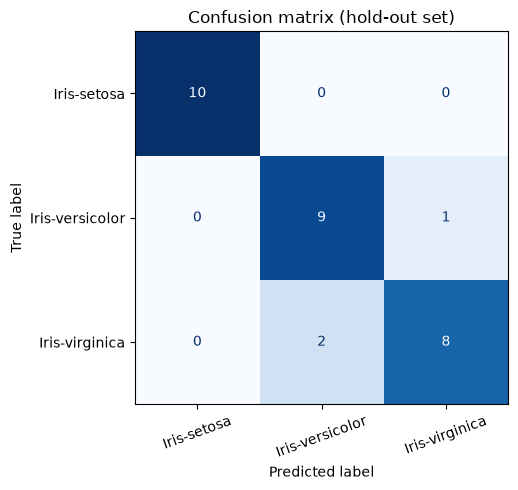

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", xticks_rotation=20, ax=ax, colorbar=False
)
ax.set_title("Confusion matrix (hold-out set)")
ax.grid(False)
plt.tight_layout()
plt.show()

With only 30 test samples, one misclassified flower moves accuracy by about 3 percentage points, so a single split is a noisy estimate. Cross-validation below gives a more reliable one.

## 6. Cross-validated model comparison

Five-fold stratified cross-validation over the full dataset, comparing the chosen Random Forest against two simple baselines.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Random Forest (chosen)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, estimator in candidates.items():
    scores = cross_val_score(estimator, X, y, cv=cv, scoring="accuracy")
    rows.append({"model": name, "mean_accuracy": scores.mean(), "std": scores.std()})

cv_results = pd.DataFrame(rows).sort_values("mean_accuracy", ascending=False).reset_index(drop=True)
cv_results.round(3)

,model,mean_accuracy,std
0,Decision Tree,0.953,0.034
1,Logistic Regression,0.953,0.045
2,Random Forest (chosen),0.947,0.027


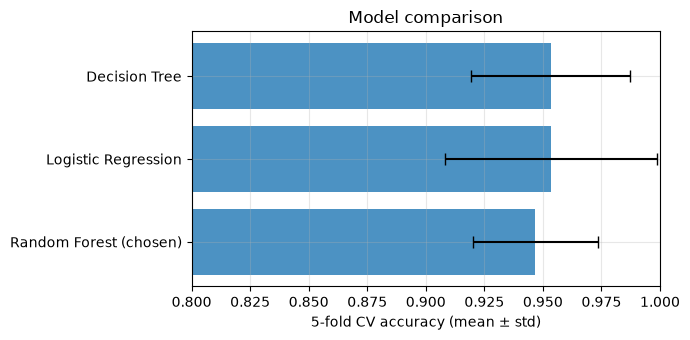

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cv_results["model"][::-1], cv_results["mean_accuracy"][::-1],
        xerr=cv_results["std"][::-1], color="tab:blue", alpha=0.8, capsize=4)
ax.set_xlim(0.8, 1.0)
ax.set_xlabel("5-fold CV accuracy (mean ± std)")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

All three models perform similarly, which is expected on a small, well-behaved dataset. The Random Forest is a sensible default: it needs no feature scaling, handles the versicolor/virginica overlap without hand-tuning, and provides class probabilities and feature importances. On data this small, differences of one or two points between models are within noise.

## 7. Feature importance

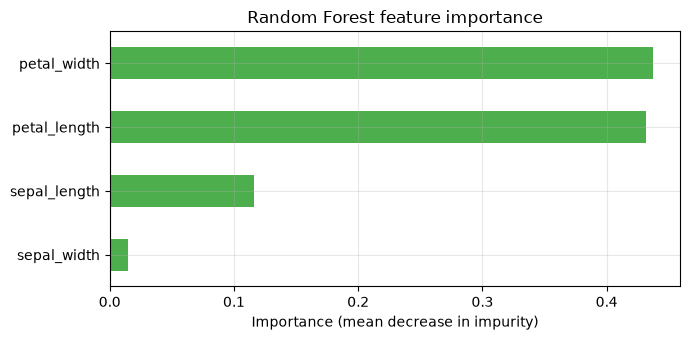

,importance
petal_width,0.437
petal_length,0.431
sepal_length,0.116
sepal_width,0.015


In [13]:
importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
importances.plot.barh(ax=ax, color="tab:green", alpha=0.85)
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False).round(3).to_frame("importance")

Petal length and petal width carry most of the predictive signal, consistent with what the EDA showed.

## 8. Verify the saved model artifact

The web app loads `model/iris_model.pkl`. Here we confirm that the saved file behaves exactly like the model trained in this notebook.

In [14]:
if not train_model.MODEL_PATH.exists():
    train_model.main()  # trains and saves the model if it hasn't been created yet

with open(train_model.MODEL_PATH, "rb") as f:
    bundle = pickle.load(f)

served_model = bundle["model"]
print("Saved classes:", bundle["target_names"])
print("Saved model matches notebook model on the test set:",
      bool(np.array_equal(served_model.predict(X_test), y_pred)))

Saved classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Saved model matches notebook model on the test set: True


## 9. Example predictions

In [15]:
examples = pd.DataFrame(
    [
        ("Typical setosa (from the app screenshot)", 5.5, 4.1, 1.6, 0.3),
        ("Typical versicolor", 5.9, 3.0, 4.2, 1.5),
        ("Typical virginica", 6.3, 3.3, 6.0, 2.5),
        ("Borderline versicolor/virginica", 6.0, 2.7, 5.0, 1.6),
    ],
    columns=["description"] + FEATURES,
)

proba = served_model.predict_proba(examples[FEATURES].values)
examples["prediction"] = [bundle["target_names"][i] for i in proba.argmax(axis=1)]
examples["confidence_%"] = (proba.max(axis=1) * 100).round(1)
examples

,description,sepal_length,sepal_width,petal_length,petal_width,prediction,confidence_%
0,Typical setosa (from the app screenshot),5.5,4.1,1.6,0.3,Iris-setosa,99.0
1,Typical versicolor,5.9,3.0,4.2,1.5,Iris-versicolor,98.0
2,Typical virginica,6.3,3.3,6.0,2.5,Iris-virginica,100.0
3,Borderline versicolor/virginica,6.0,2.7,5.0,1.6,Iris-versicolor,64.0


Confidence is expected to be high for clear cases and noticeably lower for samples near the versicolor/virginica boundary. The app displays these probabilities so users can see when the model is unsure.

## 10. End-to-end check against the FastAPI app

In [16]:
from fastapi.testclient import TestClient
from main import app

payload = {"sepal_length": 5.5, "sepal_width": 4.1, "petal_length": 1.6, "petal_width": 0.3}

with TestClient(app) as client:
    response = client.post("/predict", data=payload)

prediction = re.search(r"Prediction: (.*?)</h2>", response.text).group(1)
confidence = re.search(r"Confidence: (.*?)%", response.text).group(1)
print(f"HTTP status: {response.status_code}")
print(f"Input: {payload}")
print(f"App response: {prediction} ({confidence}% confidence)")

HTTP status: 200
Input: {'sepal_length': 5.5, 'sepal_width': 4.1, 'petal_length': 1.6, 'petal_width': 0.3}
App response: Iris-setosa (99.0% confidence)


## 11. Summary

In [17]:
best = cv_results.iloc[0]
print(f"Hold-out accuracy (30 samples):        {holdout_accuracy:.3f}")
print(f"5-fold CV accuracy (Random Forest):    "
      f"{cv_results.loc[cv_results['model'].str.startswith('Random Forest'), 'mean_accuracy'].iloc[0]:.3f}")
print(f"Top features: {', '.join(importances.sort_values(ascending=False).index[:2])}")

Hold-out accuracy (30 samples):        0.900
5-fold CV accuracy (Random Forest):    0.947
Top features: petal_width, petal_length


**Takeaways**

- The Random Forest separates the three species reliably; nearly all errors involve versicolor vs. virginica.
- Cross-validation, not the single 30-sample split, should be used when quoting performance.
- The saved `.pkl` reproduces the notebook model exactly, and the FastAPI app returns the same predictions end to end.

**Limitations and next steps**

- Iris is a small, clean teaching dataset. These results do not indicate performance on harder, noisier problems.
- Hyperparameters were left at sensible defaults; a grid or random search would be the next step on a harder task.
- For production use: add input-range monitoring, model versioning, and automated tests around the endpoint.